# Brusselator PINN


## 1. Setup


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

REPO_ROOT = Path.cwd().parent
sys.path.insert(0, str(REPO_ROOT))

from pinns.brusselator import (
    BrusselatorPINN,
    brusselator_residual,
    brusselator_source,
    solve_brusselator_reference,
)


In [2]:
SEED = 42
DEVICE = torch.device("cpu")
DTYPE = torch.float64

torch.set_num_threads(1)
torch.manual_seed(SEED)


## 2. PDE and boundary conditions


In [3]:
DEGREE = 14
PARAMETERS = {"a": 1.0, "b": 3.0, "du": 0.03, "dv": 0.02}

model = BrusselatorPINN(DEGREE, PARAMETERS, dtype=DTYPE).to(DEVICE)


## 3. Physics loss


In [4]:
INTERIOR_POINTS = 2048

engine = torch.quasirandom.SobolEngine(dimension=2, scramble=True, seed=SEED)
interior_points = (2 * engine.draw(INTERIOR_POINTS) - 1).to(dtype=DTYPE, device=DEVICE)


def pde_residual(model, points):
    return brusselator_residual(model, points, PARAMETERS)


def physics_loss():
    # The shared residual retains the second-derivative graphs for optimization.
    component_losses = pde_residual(model, interior_points).square().mean(dim=0)
    return component_losses.sum(), component_losses


## 4. Training


In [5]:
ADAM_EPOCHS = 2000

history_rows = []
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
for epoch in range(ADAM_EPOCHS):
    optimizer.zero_grad()
    loss, components = physics_loss()
    loss.backward()
    optimizer.step()
    # Adam losses are recorded before each update, matching the original workflow.
    history_rows.append(
        {
            "step": epoch + 1,
            "u_pde": components[0].item(),
            "v_pde": components[1].item(),
            "total": loss.item(),
        }
    )
    if epoch == 0 or (epoch + 1) % 500 == 0:
        print(f"Adam {epoch + 1}: PDE loss={loss.item():.3e}", flush=True)

lbfgs = torch.optim.LBFGS(
    model.parameters(),
    lr=1.0,
    max_iter=80,
    max_eval=80,
    tolerance_grad=1e-9,
    tolerance_change=1e-11,
    history_size=100,
    line_search_fn="strong_wolfe",
)


def closure():
    lbfgs.zero_grad()
    loss, _ = physics_loss()
    loss.backward()
    return loss


lbfgs.step(closure)
loss, components = physics_loss()
history_rows.append(
    {
        "step": ADAM_EPOCHS + 1,
        "u_pde": components[0].item(),
        "v_pde": components[1].item(),
        "total": loss.item(),
    }
)
history = pd.DataFrame(history_rows)
print(f"After L-BFGS: PDE loss={loss.item():.3e}", flush=True)


Adam 1: PDE loss=2.936e-02


Adam 500: PDE loss=1.285e-03


Adam 1000: PDE loss=2.519e-04


Adam 1500: PDE loss=1.052e-04


Adam 2000: PDE loss=6.321e-05


After L-BFGS: PDE loss=3.101e-05


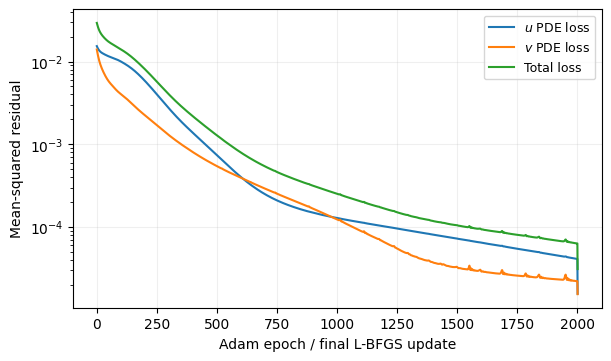

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.5), constrained_layout=True)
ax.semilogy(history["step"], history["u_pde"], label=r"$u$ PDE loss", linewidth=1.5)
ax.semilogy(history["step"], history["v_pde"], label=r"$v$ PDE loss", linewidth=1.5)
ax.semilogy(history["step"], history["total"], label="Total loss", linewidth=1.5)
ax.set(xlabel="Adam epoch / final L-BFGS update", ylabel="Mean-squared residual")
ax.grid(alpha=0.2)
ax.legend(fontsize=9)
plt.show()


## 5. Reference and prediction


In [7]:
GRID_SIZE = 129

reference = solve_brusselator_reference(GRID_SIZE, PARAMETERS)
axis = reference["axis"]
xx, yy = np.meshgrid(axis, axis, indexing="ij")
grid_points = torch.tensor(
    np.column_stack([xx.ravel(), yy.ravel()]), dtype=DTYPE, device=DEVICE
)
model.eval()
with torch.no_grad():
    prediction = model(grid_points).cpu().numpy().reshape(GRID_SIZE, GRID_SIZE, 2)
u_reference, v_reference = reference["u"], reference["v"]
u_prediction, v_prediction = prediction[:, :, 0], prediction[:, :, 1]
u_error, v_error = np.abs(u_prediction - u_reference), np.abs(
    v_prediction - v_reference
)
u_relative_l2 = np.linalg.norm(u_error) / np.linalg.norm(u_reference)
v_relative_l2 = np.linalg.norm(v_error) / np.linalg.norm(v_reference)


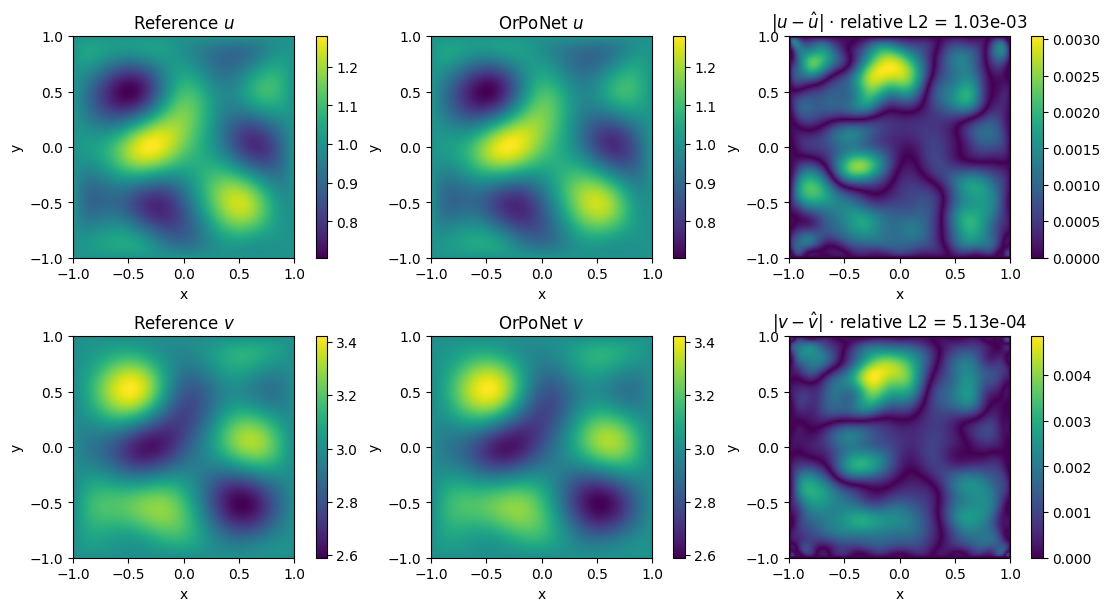

In [8]:
u_min = min(u_reference.min(), u_prediction.min())
u_max = max(u_reference.max(), u_prediction.max())
v_min = min(v_reference.min(), v_prediction.min())
v_max = max(v_reference.max(), v_prediction.max())
fig, axes = plt.subplots(2, 3, figsize=(11, 6), constrained_layout=True)
image = axes[0, 0].imshow(
    u_reference.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=u_min,
    vmax=u_max,
)
axes[0, 0].set(title=r"Reference $u$", xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes[0, 0], fraction=0.046, pad=0.04)
image = axes[0, 1].imshow(
    u_prediction.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=u_min,
    vmax=u_max,
)
axes[0, 1].set(title=r"OrPoNet $u$", xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes[0, 1], fraction=0.046, pad=0.04)
image = axes[0, 2].imshow(
    u_error.T, origin="lower", extent=[-1, 1, -1, 1], cmap="viridis", vmin=0
)
axes[0, 2].set(
    title=rf"$|u-\hat u|$ · relative L2 = {u_relative_l2:.2e}", xlabel="x", ylabel="y"
)
fig.colorbar(image, ax=axes[0, 2], fraction=0.046, pad=0.04)
image = axes[1, 0].imshow(
    v_reference.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=v_min,
    vmax=v_max,
)
axes[1, 0].set(title=r"Reference $v$", xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes[1, 0], fraction=0.046, pad=0.04)
image = axes[1, 1].imshow(
    v_prediction.T,
    origin="lower",
    extent=[-1, 1, -1, 1],
    cmap="viridis",
    vmin=v_min,
    vmax=v_max,
)
axes[1, 1].set(title=r"OrPoNet $v$", xlabel="x", ylabel="y")
fig.colorbar(image, ax=axes[1, 1], fraction=0.046, pad=0.04)
image = axes[1, 2].imshow(
    v_error.T, origin="lower", extent=[-1, 1, -1, 1], cmap="viridis", vmin=0
)
axes[1, 2].set(
    title=rf"$|v-\hat v|$ · relative L2 = {v_relative_l2:.2e}", xlabel="x", ylabel="y"
)
fig.colorbar(image, ax=axes[1, 2], fraction=0.046, pad=0.04)
plt.show()
